In [110]:
import pandas as pd
import matplotlib.pyplot as plt

In [111]:
df = pd.read_csv("ads_events.csv")

# Первичный анализ данных

In [112]:
df

,Device_id,Device_type,Datetime,Ev_type,Adv_type,Region_id,Age,Gender
0,113a29f0,iOS,2026-09-01 00:00:25,0,native,1,14.0,2.0
1,87526a62,iOS,2026-09-01 00:00:58,0,interstitial,1,57.0,2.0
2,4b94779a,iOS,2026-09-01 00:01:05,0,banner,1,61.0,2.0
3,1a70d210,iOS,2026-09-01 00:06:14,0,banner,1,30.0,1.0
4,c60de037,Desktop,2026-09-01 00:06:16,0,banner,1,21.0,1.0
...,...,...,...,...,...,...,...,...
171702,39a9cbb3,iOS,2026-09-30 23:58:50,0,interstitial,1,28.0,2.0
171703,ffe050a3,iOS,2026-09-30 23:58:51,0,video,1,36.0,1.0
171704,3166beb2,Android,2026-09-30 23:59:12,0,interstitial,2,45.0,2.0
171705,5745ac10,Android,2026-09-30 23:59:16,0,banner,2,29.0,2.0


In [113]:
df.describe()

,Ev_type,Region_id,Age,Gender
count,171707.000000,171707.000000,159971.000000,161411.000000
mean,0.029702,1.421654,34.720143,1.484868
std,0.169764,0.493825,11.600394,0.499773
min,0.000000,1.000000,14.000000,1.000000
25%,0.000000,1.000000,26.000000,1.000000
50%,0.000000,1.000000,33.000000,1.000000
75%,0.000000,2.000000,42.000000,2.000000
max,1.000000,2.000000,70.000000,2.000000


пустые значения в age, gender - есть ли в данных с пропуском информация или это шум? Выбросов значений нет, распределение не скошенное

# изучим нулевые значения

In [114]:
df[df["Age"].isna()].describe()

,Ev_type,Region_id,Age,Gender
count,11736.000000,11736.000000,0.0,4724.000000
mean,0.003408,1.398091,NaN,1.503387
std,0.058284,0.489525,NaN,0.500041
min,0.000000,1.000000,NaN,1.000000
25%,0.000000,1.000000,NaN,1.000000
50%,0.000000,1.000000,NaN,2.000000
75%,0.000000,2.000000,NaN,2.000000
max,1.000000,2.000000,NaN,2.000000


In [115]:
df[df["Gender"].isna()].describe()

,Ev_type,Region_id,Age,Gender
count,10296.000000,10296.000000,3284.000000,0.0
mean,0.009615,1.378594,33.987515,NaN
std,0.097590,0.485060,12.093912,NaN
min,0.000000,1.000000,14.000000,NaN
25%,0.000000,1.000000,25.000000,NaN
50%,0.000000,1.000000,31.000000,NaN
75%,0.000000,2.000000,43.000000,NaN
max,1.000000,2.000000,70.000000,NaN


Данные содержат корректную информацию в остальных атрибутах - заполним пропуски средним значением, так как выбросов нет

In [116]:
df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Gender'] = df['Gender'].fillna(df['Gender'].mean())

In [117]:
df.describe()

,Ev_type,Region_id,Age,Gender
count,171707.000000,171707.000000,171707.000000,171707.000000
mean,0.029702,1.421654,34.720143,1.484868
std,0.169764,0.493825,11.196938,0.484557
min,0.000000,1.000000,14.000000,1.000000
25%,0.000000,1.000000,27.000000,1.000000
50%,0.000000,1.000000,34.000000,1.484868
75%,0.000000,2.000000,42.000000,2.000000
max,1.000000,2.000000,70.000000,2.000000


# Изучим поведение каждого типа девайса

In [118]:
df['Device_type'].unique()

array(['iOS', 'Desktop', 'Android'], dtype=object)

# iOS

In [163]:
iOS_df = df[df['Device_type'] == 'iOS']

In [164]:
cnt_ads_iOS = iOS_df['Ev_type'].value_counts()
cnt_ads_iOS

Ev_type
0    48474
1     1888
Name: count, dtype: int64

## Найдём, на сколько процентов из всей рекламы пользователь откликнулся

In [165]:
cnt_ads[1]/cnt_ads.sum()*100

np.float64(3.748858266153052)

## На какой тип больше всего откликался

In [166]:
cnt_ads_types_iOS = iOS_df[iOS_df['Ev_type'] == 1]['Adv_type'].value_counts()
cnt_ads_types_iOS

Adv_type
video           745
native          615
banner          379
interstitial    149
Name: count, dtype: int64

<Axes: xlabel='Adv_type'>

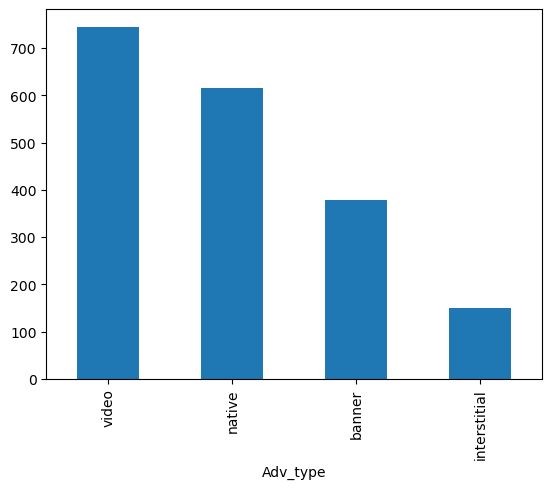

In [167]:
cnt_ads_types_iOS.plot(kind='bar')

## На какой лучше всего откликались

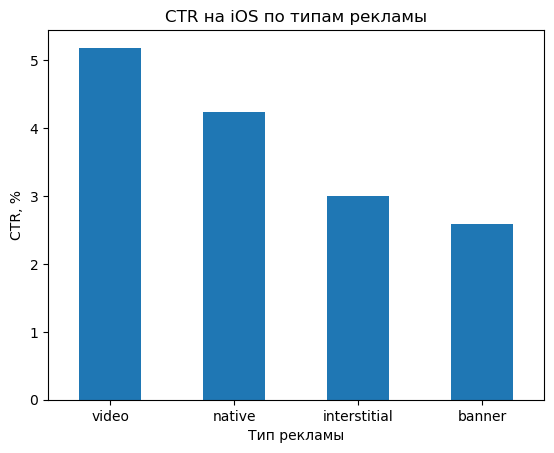

In [168]:
ctr_iOS = (iOS_df[iOS_df['Ev_type'] == 1].groupby('Adv_type').size()
       / iOS_df[iOS_df['Ev_type'] == 0].groupby('Adv_type').size() * 100
      ).sort_values(ascending=False)

ctr_iOS.plot(kind='bar', rot=0)
plt.title('CTR на iOS по типам рекламы')
plt.xlabel('Тип рекламы')
plt.ylabel('CTR, %')
plt.show()

### Вывод
Всего среди пользователей iOS на рекламу реагировали в чуть меньше 4% случаев, самый результативный тип - видео, наименее результативный - баннер

# Android

In [169]:
Android_df = df[df['Device_type'] == 'Android']

In [170]:
cnt_ads_android = Android_df['Ev_type'].value_counts()
cnt_ads_android

Ev_type
0    89822
1     2716
Name: count, dtype: int64

## Найдём, на сколько процентов из всей рекламы пользователь откликнулся

In [171]:
cnt_ads_android[1]/cnt_ads_android.sum()*100

np.float64(2.9350104821802936)

## На какой тип больше всего откликался

In [172]:
cnt_ads_types_android = Android_df[Android_df['Ev_type'] == 1]['Adv_type'].value_counts()
cnt_ads_types_android

Adv_type
video           770
native          659
banner          647
interstitial    640
Name: count, dtype: int64

<Axes: xlabel='Adv_type'>

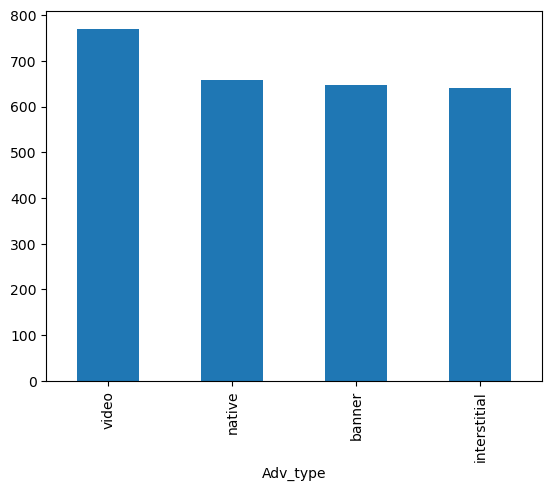

In [173]:
cnt_ads_types_android.plot(kind = "bar")

## На какой лучше всего откликались

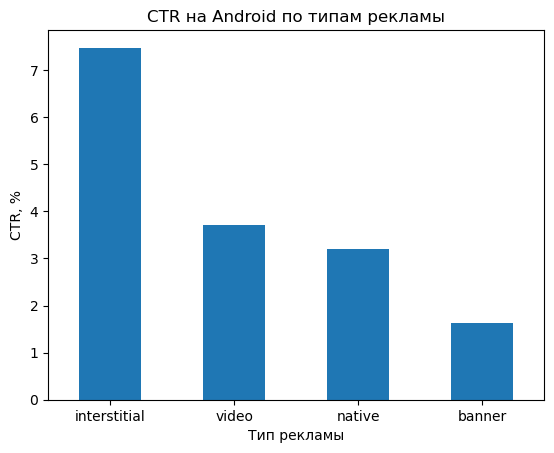

In [174]:
ctr_android = (Android_df[Android_df['Ev_type'] == 1].groupby('Adv_type').size()
       / Android_df[Android_df['Ev_type'] == 0].groupby('Adv_type').size() * 100
      ).sort_values(ascending=False)

ctr_android.plot(kind='bar', rot=0)
plt.title('CTR на Android по типам рекламы')
plt.xlabel('Тип рекламы')
plt.ylabel('CTR, %')
plt.show()

### Вывод
Всего среди пользователей Android на рекламу реагировали примерно в 3% случаев, самый результативный тип - межстраничный, наименее результативный - баннер. У всех близкие значения по тому, сколько раз кликнули, но наибольшая доля успеха у межстраничного типа, наименее - у баннера

# ПК

In [175]:
desktop_df = df[df['Device_type'] == 'Desktop']

In [176]:
cnt_ads_desktop = desktop_df['Ev_type'].value_counts()
cnt_ads_desktop

Ev_type
0    28311
1      496
Name: count, dtype: int64

## Найдём, на сколько процентов из всей рекламы пользователь откликнулся

In [177]:
cnt_ads_desktop[1]/cnt_ads_desktop.sum()*100

np.float64(1.7218037282604923)

## На какой тип больше всего откликался

In [178]:
cnt_ads_types_desktop = desktop_df[desktop_df['Ev_type'] == 1]['Adv_type'].value_counts()
cnt_ads_types_desktop

Adv_type
banner          241
video           121
native          100
interstitial     34
Name: count, dtype: int64

<Axes: xlabel='Adv_type'>

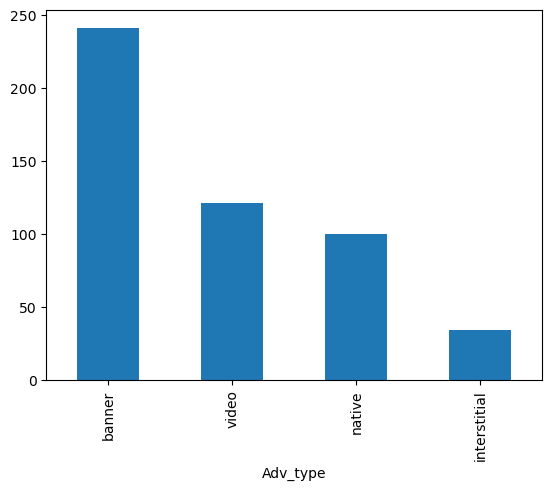

In [179]:
cnt_ads_types_desktop.plot(kind = "bar")

## На какой лучше всего откликались

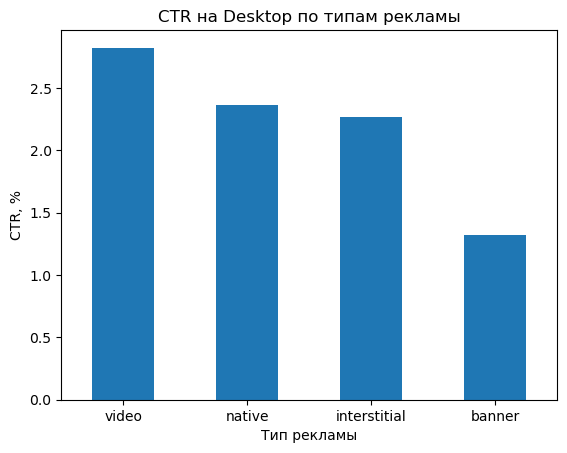

In [180]:
ctr_desktop = (desktop_df[desktop_df['Ev_type'] == 1].groupby('Adv_type').size()
       / desktop_df[desktop_df['Ev_type'] == 0].groupby('Adv_type').size() * 100
      ).sort_values(ascending=False)

ctr_desktop.plot(kind='bar', rot=0)
plt.title('CTR на Desktop по типам рекламы')
plt.xlabel('Тип рекламы')
plt.ylabel('CTR, %')
plt.show()

### Вывод
Всего среди пользователей Desktop на рекламу реагировали примерно в 2% случаев, самый результативный - видео: при втором месте по общим откликам у него наибольшая конверсия, худший - баннер: несмотря на то, что у него много откликов, конверсия маленькая, следовательно, в первом случае баннер выиграл за счёт кол-ва, а не кач-ва

# Общий вывод по анализу девайсов

| Тип | Общий процент отклика | Лучший | Худший |
|---|---:|---|---|
| iOS | 3,75 | video | banner |
| Android | 2,94 | interstitial | banner |
| Desk | 1,72 | video | banner |

Самый большой отклик у iOS, наименьший у Desk, во всех случаях самым худшим методом по конверсии оказался banner - стоит ли ему уделять время? Лучшим является video, после interstitial, наибольший приоритет должен быть у них для всех устройств